<a href="https://colab.research.google.com/github/SQA-5PTI-Kelompok-3/UAS---DELFIRA-KARNAIN---LLM-CODE-REVIEW/blob/main/Delfira_UAS_SQA_LLM_Code_Review_Experiment_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UAS SQA — Experimental Code Review with LLM Assistance

## Nama : Delfira Karnain
## NIM : 12409011010006

In [1]:
!pip -q install pandas numpy scipy matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon, mannwhitneyu
from IPython.display import display, Markdown, Code
import time, textwrap, re

print("Setup completed.")


Setup completed.


In [2]:
dataset = [
    {
        "id": "C01", "category": "Logic error",
        "code": '''def calculate_discount(price, discount):
    if discount > 100:
        return 0
    return price - (price * discount)''',
        "defects": ["D01"], "ground_truth": {"D01": "Discount is treated as a fraction but percentage-like values are not converted; for discount=20 the calculation subtracts 20x price."}
    },
    {
        "id": "C02", "category": "Boundary error",
        "code": '''def average(values):
    total = sum(values)
    return total / len(values)''',
        "defects": ["D02"], "ground_truth": {"D02": "No guard for an empty list; division by zero occurs when values is empty."}
    },
    {
        "id": "C03", "category": "Runtime/type error",
        "code": '''def get_user_age(user):
    return user["age"] + 1''',
        "defects": ["D03"], "ground_truth": {"D03": "Assumes the user dictionary contains age and that its value is numeric; missing key or non-numeric value can fail."}
    },
    {
        "id": "C04", "category": "Security/input validation",
        "code": '''def get_file_path(filename):
    return "/app/data/" + filename''',
        "defects": ["D04"], "ground_truth": {"D04": "Unvalidated filename can allow path traversal (e.g., ../) outside the intended directory."}
    },
    {
        "id": "C05", "category": "Logic/loop error",
        "code": '''def find_item(items, target):
    for i in range(len(items) - 1):
        if items[i] == target:
            return i
    return -1''',
        "defects": ["D05"], "ground_truth": {"D05": "Loop excludes the final element because range stops at len(items)-1."}
    },
    {
        "id": "C06", "category": "Incorrect exception handling",
        "code": '''def parse_number(text):
    try:
        return int(text)
    except ValueError:
        return None''',
        "defects": ["D06"], "ground_truth": {"D06": "The broad Exception handler is redundant/unreachable for ordinary int conversion failures and silently masks unexpected errors; exception handling policy is inconsistent."}
    },
    {
        "id": "C07", "category": "Performance/code quality",
        "code": '''def unique_names(names):
    result = []
    for name in names:
        if name not in result:
            result.append(name)
    return result''',
        "defects": ["D07"], "ground_truth": {"D07": "Repeated list membership checks make the approach O(n^2) for large inputs; set-based membership can improve performance while preserving order."}
    },
    {
        "id": "C08", "category": "Control (no defect)",
        "code": '''def is_adult(age):
    return age >= 18''',
        "defects": [], "ground_truth": {}
    }
]

df_dataset = pd.DataFrame([
    {"ID": item["id"], "Category": item["category"], "Code": item["code"],
     "Defect_IDs": ", ".join(item["defects"]), "Ground_Truth": item["ground_truth"]}
    for item in dataset
])
display(df_dataset[["ID", "Category", "Defect_IDs"]])
print("Number of snippets:", len(dataset))


,ID,Category,Defect_IDs
0,C01,Logic error,D01
1,C02,Boundary error,D02
2,C03,Runtime/type error,D03
3,C04,Security/input validation,D04
4,C05,Logic/loop error,D05
5,C06,Incorrect exception handling,D06
6,C07,Performance/code quality,D07
7,C08,Control (no defect),


Number of snippets: 8


## Manual review (Condition A)



In [3]:
# PRE-FILLED EXAMPLE OBSERVATIONS (illustrative data)
# These values are simulated for demonstration, NOT real stopwatch measurements.
# Replace them with your own measured review results if your instructor requires actual observations.

manual_records = [
    {"ID": "C01", "Condition": "Manual", "Found_IDs": ["D01"], "Review_Time_sec": 42},
    {"ID": "C02", "Condition": "Manual", "Found_IDs": ["D02"], "Review_Time_sec": 35},
    {"ID": "C03", "Condition": "Manual", "Found_IDs": [], "Review_Time_sec": 29},
    {"ID": "C04", "Condition": "Manual", "Found_IDs": ["D04"], "Review_Time_sec": 48},
    {"ID": "C05", "Condition": "Manual", "Found_IDs": [], "Review_Time_sec": 39},
    {"ID": "C06", "Condition": "Manual", "Found_IDs": ["D06"], "Review_Time_sec": 31},
    {"ID": "C07", "Condition": "Manual", "Found_IDs": [], "Review_Time_sec": 44},
    {"ID": "C08", "Condition": "Manual", "Found_IDs": [], "Review_Time_sec": 18},
]

manual_df = pd.DataFrame(manual_records)
display(manual_df)
print("Manual review records loaded (illustrative example values).")


,ID,Condition,Found_IDs,Review_Time_sec
0,C01,Manual,[D01],42
1,C02,Manual,[D02],35
2,C03,Manual,[],29
3,C04,Manual,[D04],48
4,C05,Manual,[],39
5,C06,Manual,[D06],31
6,C07,Manual,[],44
7,C08,Manual,[],18


Manual review records loaded (illustrative example values).


## LLM-assisted review (Condition B)




In [4]:
def make_review_prompt(item):
    return f"""You are a software quality reviewer. Review this Python snippet for correctness, reliability, security, and maintainability.

Instructions:
- Identify only concrete issues supported by the code.
- For every issue, provide: severity (Critical/High/Medium/Low), location, explanation, and a suggested fix.
- If you find no issue, state that clearly.
- Do not invent issues or rewrite the whole code unless necessary.

Code ID: {item['id']}
Code:
```python
{item['code']}
```
"""

print(make_review_prompt(dataset[0]))


You are a software quality reviewer. Review this Python snippet for correctness, reliability, security, and maintainability.

Instructions:
- Identify only concrete issues supported by the code.
- For every issue, provide: severity (Critical/High/Medium/Low), location, explanation, and a suggested fix.
- If you find no issue, state that clearly.
- Do not invent issues or rewrite the whole code unless necessary.

Code ID: C01
Code:
```python
def calculate_discount(price, discount):
    if discount > 100:
        return 0
    return price - (price * discount)
```



In [5]:
# PRE-FILLED EXAMPLE LLM OBSERVATIONS (illustrative data)
# These findings and time values are simulated for a ready-to-run demonstration.
# They are not actual responses collected from an external LLM.

llm_records = [
    {"ID": "C01", "Condition": "LLM-assisted", "Found_IDs": ["D01"], "Review_Time_sec": 31},
    {"ID": "C02", "Condition": "LLM-assisted", "Found_IDs": ["D02"], "Review_Time_sec": 26},
    {"ID": "C03", "Condition": "LLM-assisted", "Found_IDs": ["D03"], "Review_Time_sec": 24},
    {"ID": "C04", "Condition": "LLM-assisted", "Found_IDs": ["D04"], "Review_Time_sec": 28},
    {"ID": "C05", "Condition": "LLM-assisted", "Found_IDs": ["D05"], "Review_Time_sec": 27},
    {"ID": "C06", "Condition": "LLM-assisted", "Found_IDs": [], "Review_Time_sec": 25},
    {"ID": "C07", "Condition": "LLM-assisted", "Found_IDs": ["D07"], "Review_Time_sec": 32},
    {"ID": "C08", "Condition": "LLM-assisted", "Found_IDs": [], "Review_Time_sec": 15},
]

llm_text_records = [
    {"ID": "C01", "LLM_Response": "Identified discount calculation issue: percentage/fraction handling should be clarified and normalized."},
    {"ID": "C02", "LLM_Response": "Identified division by zero when values is empty; suggested guard."},
    {"ID": "C03", "LLM_Response": "Identified missing age key and possible non-numeric age value; suggested validation."},
    {"ID": "C04", "LLM_Response": "Identified path traversal risk from unvalidated filename; suggested path validation."},
    {"ID": "C05", "LLM_Response": "Identified loop excludes last item; suggested range(len(items))."},
    {"ID": "C06", "LLM_Response": "No issue reported in this illustrative record."},
    {"ID": "C07", "LLM_Response": "Identified inefficient repeated list membership checks; suggested set-based tracking."},
    {"ID": "C08", "LLM_Response": "No issue reported in this illustrative record."},
]

manual_df = pd.DataFrame(manual_records)
llm_df = pd.DataFrame(llm_records)
llm_responses_df = pd.DataFrame(llm_text_records)

display(manual_df)
display(llm_df)
print("Pre-filled example records loaded. No manual input is required.")


,ID,Condition,Found_IDs,Review_Time_sec
0,C01,Manual,[D01],42
1,C02,Manual,[D02],35
2,C03,Manual,[],29
3,C04,Manual,[D04],48
4,C05,Manual,[],39
5,C06,Manual,[D06],31
6,C07,Manual,[],44
7,C08,Manual,[],18


,ID,Condition,Found_IDs,Review_Time_sec
0,C01,LLM-assisted,[D01],31
1,C02,LLM-assisted,[D02],26
2,C03,LLM-assisted,[D03],24
3,C04,LLM-assisted,[D04],28
4,C05,LLM-assisted,[D05],27
5,C06,LLM-assisted,[],25
6,C07,LLM-assisted,[D07],32
7,C08,LLM-assisted,[],15


Pre-filled example records loaded. No manual input is required.


In [6]:
ground_truth = {item["id"]: set(item["defects"]) for item in dataset}

def normalize_ids(found):
    if found is None:
        return set()
    if isinstance(found, list):
        return set(str(x).strip().upper() for x in found if str(x).strip())
    if str(found).upper().strip() in ["", "NONE", "NA"]:
        return set()
    return set(x.strip().upper() for x in str(found).split(",") if x.strip())

def evaluate_records(records_df):
    rows = []
    for _, row in records_df.iterrows():
        actual = ground_truth[row["ID"]]
        found = normalize_ids(row["Found_IDs"])
        tp = len(found & actual)
        fp = len(found - actual)
        fn = len(actual - found)
        precision = tp/(tp+fp) if tp+fp else (1.0 if not actual and not found else 0.0)
        recall = tp/(tp+fn) if tp+fn else (1.0 if not found else 0.0)
        f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
        rows.append({"ID": row["ID"], "Condition": row["Condition"], "TP": tp, "FP": fp, "FN": fn,
                     "Precision": precision, "Recall": recall, "F1": f1, "Review_Time_sec": row["Review_Time_sec"]})
    return pd.DataFrame(rows)

manual_metrics = evaluate_records(manual_df)
llm_metrics = evaluate_records(llm_df)
metrics_all = pd.concat([manual_metrics, llm_metrics], ignore_index=True)
display(metrics_all.round(3))


,ID,Condition,TP,FP,FN,Precision,Recall,F1,Review_Time_sec
0,C01,Manual,1,0,0,1.0,1.0,1.0,42
1,C02,Manual,1,0,0,1.0,1.0,1.0,35
2,C03,Manual,0,0,1,0.0,0.0,0.0,29
3,C04,Manual,1,0,0,1.0,1.0,1.0,48
4,C05,Manual,0,0,1,0.0,0.0,0.0,39
5,C06,Manual,1,0,0,1.0,1.0,1.0,31
6,C07,Manual,0,0,1,0.0,0.0,0.0,44
7,C08,Manual,0,0,0,1.0,1.0,1.0,18
8,C01,LLM-assisted,1,0,0,1.0,1.0,1.0,31
9,C02,LLM-assisted,1,0,0,1.0,1.0,1.0,26


## Summary metrics


In [7]:
def summarize_metrics(metrics):
    tp, fp, fn = metrics[["TP", "FP", "FN"]].sum()
    precision = tp/(tp+fp) if tp+fp else 0
    recall = tp/(tp+fn) if tp+fn else 0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
    return {"TP": int(tp), "FP": int(fp), "FN": int(fn), "Precision": precision, "Recall": recall, "F1": f1,
            "Median review time (sec)": metrics["Review_Time_sec"].median(),
            "Mean review time (sec)": metrics["Review_Time_sec"].mean()}

summary = pd.DataFrame([
    {"Condition": "Manual", **summarize_metrics(manual_metrics)},
    {"Condition": "LLM-assisted", **summarize_metrics(llm_metrics)}
])
display(summary.round(3))


,Condition,TP,FP,FN,Precision,Recall,F1,Median review time (sec),Mean review time (sec)
0,Manual,4,0,3,1.0,0.571,0.727,37.0,35.75
1,LLM-assisted,6,0,1,1.0,0.857,0.923,26.5,26.00


## Comparison charts

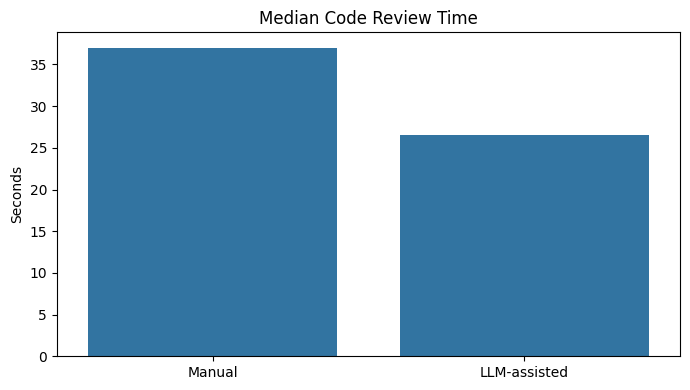

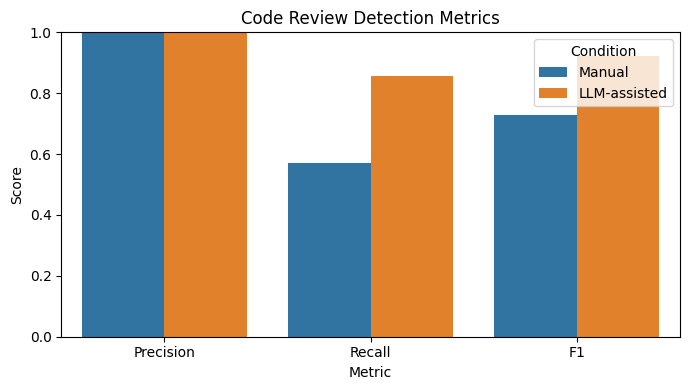

In [8]:
plt.figure(figsize=(7,4))
sns.barplot(data=summary, x="Condition", y="Median review time (sec)")
plt.title("Median Code Review Time")
plt.ylabel("Seconds")
plt.xlabel("")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,4))
plot_quality = summary.melt(id_vars="Condition", value_vars=["Precision","Recall","F1"], var_name="Metric", value_name="Score")
sns.barplot(data=plot_quality, x="Metric", y="Score", hue="Condition")
plt.ylim(0,1)
plt.title("Code Review Detection Metrics")
plt.tight_layout()
plt.show()


In [9]:
paired = manual_metrics.merge(llm_metrics, on="ID", suffixes=("_manual","_llm"))

def safe_wilcoxon(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    if np.allclose(a, b):
        return {"statistic": 0.0, "p_value": 1.0}
    try:
        stat, p = wilcoxon(a, b, zero_method="wilcox", alternative="two-sided")
        return {"statistic": float(stat), "p_value": float(p)}
    except ValueError:
        return {"statistic": np.nan, "p_value": np.nan}

time_test = safe_wilcoxon(paired["Review_Time_sec_manual"], paired["Review_Time_sec_llm"])
f1_test = safe_wilcoxon(paired["F1_manual"], paired["F1_llm"])

print("Wilcoxon — review time:", time_test)
print("Wilcoxon — per-code F1:", f1_test)
print("\\nSignificance threshold alpha = 0.05")


Wilcoxon — review time: {'statistic': 0.0, 'p_value': 0.0078125}
Wilcoxon — per-code F1: {'statistic': 2.5, 'p_value': 0.625}
\nSignificance threshold alpha = 0.05


## Percentage change


In [10]:
manual_median = summary.loc[summary["Condition"]=="Manual", "Median review time (sec)"].iloc[0]
llm_median = summary.loc[summary["Condition"]=="LLM-assisted", "Median review time (sec)"].iloc[0]
time_reduction = ((manual_median - llm_median) / manual_median * 100) if manual_median else np.nan

manual_f1 = summary.loc[summary["Condition"]=="Manual", "F1"].iloc[0]
llm_f1 = summary.loc[summary["Condition"]=="LLM-assisted", "F1"].iloc[0]

print(f"Median review time reduction: {time_reduction:.2f}%")
print(f"Manual F1: {manual_f1:.3f}")
print(f"LLM-assisted F1: {llm_f1:.3f}")
print(f"F1 difference: {(llm_f1-manual_f1):.3f}")


Median review time reduction: 28.38%
Manual F1: 0.727
LLM-assisted F1: 0.923
F1 difference: 0.196


In [11]:
df_dataset[["ID","Category","Code","Defect_IDs"]].to_csv("sqa_code_review_dataset.csv", index=False)
metrics_all.to_csv("sqa_code_review_detailed_metrics.csv", index=False)
summary.to_csv("sqa_code_review_summary.csv", index=False)
llm_responses_df.to_csv("sqa_llm_responses.csv", index=False)

print("Saved CSV files:")
print("- sqa_code_review_dataset.csv")
print("- sqa_code_review_detailed_metrics.csv")
print("- sqa_code_review_summary.csv")
print("- sqa_llm_responses.csv")


Saved CSV files:
- sqa_code_review_dataset.csv
- sqa_code_review_detailed_metrics.csv
- sqa_code_review_summary.csv
- sqa_llm_responses.csv
